# Limpeza da base de manutenção corretiva emergencial — ZM01

Este notebook consolida uma rotina reproduzível de limpeza da extração ZM01. A base original é preservada, transformações são aplicadas em cópias e registros removidos por duração extrema ficam disponíveis para auditoria.

Etapas: diagnóstico, padronização, tratamento temporal e textual, validação de duplicidades, análise de outliers, preparação da base final e exportação.

## 1. Importação e diagnóstico inicial

In [1]:
from datetime import time
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 40)

caminho = "../../data/Corretiva Emergencial/Ordens do SAP - Corretiva emergencial (ZM01).XLSX"
df = pd.read_excel(caminho, sheet_name="Corretivas")

print(f"Dimensão original: {df.shape[0]} linhas e {df.shape[1]} colunas")
df.head(3)

Dimensão original: 10647 linhas e 28 colunas


,Tipo de Nota,Nota,Ordem,Indisponível,Falha,IQM,Analisada,Comentários Classificação Engenharia,Perfil do catálogo,Descrição,Local de Instalação,Status do Usuário da Ordem,Texto Longo da Ordem,Status do Sistema da Ordem,Início avaria,Hora início avaria,Fim da avaria,Hora do fim da avaria,Centro de Trabalho Responsável,Sintoma,Objeto,Defeito,Causa,Ação,Data Análise,Hora Análise,Encerram.por Data,Hora de Encerramento
0,Z1,14943931,53954586.0,X,X,NaN,NaN,MI/ NVT1 - AVARIADA,6PSD,PSD PL 01-02 Sem status para o CCO,SP04-6-PSD-BUT,OPER EXPR ANEX,PSD PL 01-02 Sem status para o CCO 14.11.2025 ...,LIB CNPA CAPC ERRD MOME MatC NOLQ,14/11/2025,06:35:28,NaN,00:00:00,SP04IBUT,LAÇO DE PDM ABERTO,NaN,NaN,NaN,NaN,2025-12-05,17:50:50,NaT,00:00:00
1,Z1,15133619,54145839.0,NaN,NaN,NaN,X,DU,6PSD,PSD - PDM's não abriram PLT02,SP04-6-PSD-BUT,LIBO EXDO,PSD - PDM's não abriram PLT02 27.02.2026 14:20...,ENTE CNPA CAPC NOLQ SCDM,27/02/2026,07:33:00,27/02/2026,12:00:00,SP04IBUT,TODAS AS PDM DA FACHADA NÃO ABREM,CABEAMENTO,CONTROLADOR PCC COMUNICACAO,ERRO DE COMUNICAÇÃO,RESETADO E TESTADO,2026-03-03,17:48:50,2026-02-27,14:26:36
2,Z1,13894133,52913343.0,NaN,NaN,NaN,X,CF/FALHA COMUNICAÇÃO,6PSD,PSD server s/ status das plataformas,SP04-6-PSD-BUT-P1S1,LIBO EXDO,PSD server s/ status das plataformas 18.04.202...,ENTE CNPA CAPC NOLQ SCDM,18/04/2024,06:00:00,18/04/2024,07:30:00,SP04IBUT,PSD SERVER COM INDICAÇÃO DE FALHA NA PLA,RACK WCN,SENSOR DESTRAVADO AVARIADO,DESGASTE,RESETADO E TESTADO,NaT,00:00:00,2024-04-18,07:33:25


In [2]:
diagnostico_inicial = pd.Series({
    "linhas": len(df),
    "colunas": df.shape[1],
    "ordens_ausentes": df["Ordem"].isna().sum(),
    "ordens_repetidas_excedentes": df["Ordem"].duplicated().sum(),
    "notas_repetidas_excedentes": df["Nota"].duplicated().sum(),
    "linhas_totalmente_duplicadas": df.duplicated().sum(),
})

diagnostico_inicial

linhas                          10647
colunas                            28
ordens_ausentes                     2
ordens_repetidas_excedentes        72
notas_repetidas_excedentes         71
linhas_totalmente_duplicadas        1
dtype: int64

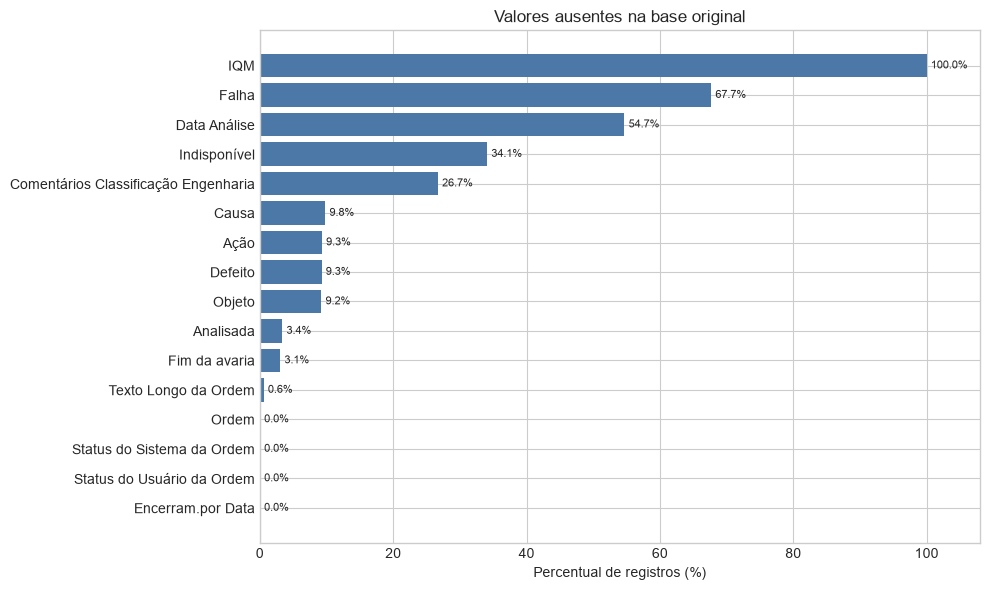

In [3]:
ausentes_iniciais = (
    df.isna().mean().mul(100).sort_values(ascending=True)
)
ausentes_iniciais = ausentes_iniciais[ausentes_iniciais > 0]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ausentes_iniciais.index, ausentes_iniciais.values, color="#4C78A8")
ax.set(title="Valores ausentes na base original", xlabel="Percentual de registros (%)", ylabel="")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xlim(0, 108)
plt.tight_layout()
plt.show()

## 2. Padronização estrutural

Os identificadores são tratados como texto, os nomes das colunas são normalizados e a linha de origem é preservada para rastreabilidade.

In [4]:
def normalizar_coluna(nome):
    nome = str(nome).strip().lower()
    nome = unicodedata.normalize("NFKD", nome)
    nome = nome.encode("ascii", "ignore").decode("ascii")
    nome = re.sub(r"[^a-z0-9]+", "_", nome)
    return nome.strip("_")


df_limpo = df.copy()
df_limpo.columns = [normalizar_coluna(coluna) for coluna in df_limpo.columns]
df_limpo["linha_origem"] = df_limpo.index + 2

for coluna in ["nota", "ordem"]:
    df_limpo[coluna] = (
        df_limpo[coluna]
        .astype("string")
        .str.strip()
        .str.replace(r".0$", "", regex=True)
    )

assert not df_limpo.columns.duplicated().any()
df_limpo[["linha_origem", "nota", "ordem"]].head()

,linha_origem,nota,ordem
0,2,14943931,53954586
1,3,15133619,54145839
2,4,13894133,52913343
3,5,14713349,53724958
4,6,14643768,53655728


## 3. Datas e horários

Datas e horários são convertidos separadamente e depois combinados em instantes completos. As colunas originais só serão descartadas na preparação da base final.

In [5]:
def converter_data(serie):
    if pd.api.types.is_datetime64_any_dtype(serie):
        return pd.to_datetime(serie, errors="coerce")

    numeros = pd.to_numeric(serie, errors="coerce")
    valores_numericos = numeros.notna()

    datas_texto = pd.to_datetime(
        serie.where(~valores_numericos), errors="coerce", dayfirst=True
    )
    datas_excel = pd.to_datetime(
        numeros.where(valores_numericos),
        errors="coerce",
        unit="D",
        origin="1899-12-30",
    )
    return datas_texto.fillna(datas_excel)


def converter_hora(valor):
    if pd.isna(valor):
        return pd.NaT
    if isinstance(valor, time):
        return pd.Timedelta(hours=valor.hour, minutes=valor.minute, seconds=valor.second)

    try:
        numero = float(valor)
        if 0 <= numero < 1:
            return pd.to_timedelta(numero, unit="D")
    except (TypeError, ValueError):
        pass

    horario = pd.to_datetime(str(valor), errors="coerce")
    if pd.isna(horario):
        return pd.NaT
    return pd.Timedelta(hours=horario.hour, minutes=horario.minute, seconds=horario.second)

In [6]:
colunas_data = ["inicio_avaria", "fim_da_avaria", "data_analise", "encerram_por_data"]
colunas_hora = [
    "hora_inicio_avaria",
    "hora_do_fim_da_avaria",
    "hora_analise",
    "hora_de_encerramento",
]

invalidos_data = {}
for coluna in colunas_data:
    original_coluna = df_limpo[coluna].copy()
    convertida = converter_data(original_coluna)
    invalidos_data[coluna] = int((original_coluna.notna() & convertida.isna()).sum())
    df_limpo[coluna] = convertida

invalidos_hora = {}
for coluna in colunas_hora:
    nova_coluna = f"{coluna}_convertida"
    df_limpo[nova_coluna] = df_limpo[coluna].apply(converter_hora)
    invalidos_hora[coluna] = int(
        (df_limpo[coluna].notna() & df_limpo[nova_coluna].isna()).sum()
    )

pd.DataFrame({"datas_invalidas": pd.Series(invalidos_data), "horas_invalidas": pd.Series(invalidos_hora)})

,datas_invalidas,horas_invalidas
data_analise,0.0,NaN
encerram_por_data,0.0,NaN
fim_da_avaria,0.0,NaN
hora_analise,NaN,0.0
hora_de_encerramento,NaN,0.0
hora_do_fim_da_avaria,NaN,0.0
hora_inicio_avaria,NaN,0.0
inicio_avaria,0.0,NaN


In [7]:
df_limpo["inicio_avaria_datetime"] = df_limpo["inicio_avaria"] + df_limpo["hora_inicio_avaria_convertida"]
df_limpo["fim_avaria_datetime"] = df_limpo["fim_da_avaria"] + df_limpo["hora_do_fim_da_avaria_convertida"]
df_limpo["analise_datetime"] = df_limpo["data_analise"] + df_limpo["hora_analise_convertida"]
df_limpo["encerramento_datetime"] = df_limpo["encerram_por_data"] + df_limpo["hora_de_encerramento_convertida"]

validacao_temporal = pd.Series({
    "inicios_ausentes": df_limpo["inicio_avaria_datetime"].isna().sum(),
    "fins_ausentes": df_limpo["fim_avaria_datetime"].isna().sum(),
    "fim_anterior_ao_inicio": (
        df_limpo["fim_avaria_datetime"] < df_limpo["inicio_avaria_datetime"]
    ).sum(),
    "encerramento_anterior_ao_inicio": (
        df_limpo["encerramento_datetime"] < df_limpo["inicio_avaria_datetime"]
    ).sum(),
})

validacao_temporal

inicios_ausentes                     0
fins_ausentes                      326
fim_anterior_ao_inicio               0
encerramento_anterior_ao_inicio      0
dtype: int64

## 4. Limpeza textual e indicadores

Espaços invisíveis, repetições de espaços e strings vazias são normalizados. As marcações `X` são convertidas em indicadores booleanos.

In [8]:
def limpar_texto(serie, maiusculo=False):
    serie = (
        serie.astype("string")
        .str.replace(" ", " ", regex=False)
        .str.replace(r"[ \t]+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )
    return serie.str.upper() if maiusculo else serie


colunas_categoricas = [
    "tipo_de_nota", "indisponivel", "falha", "analisada", "perfil_do_catalogo",
    "local_de_instalacao", "status_do_usuario_da_ordem", "status_do_sistema_da_ordem",
    "centro_de_trabalho_responsavel", "sintoma", "objeto", "defeito", "causa", "acao",
]
colunas_descritivas = [
    "comentarios_classificacao_engenharia", "descricao", "texto_longo_da_ordem"
]

for coluna in colunas_categoricas:
    df_limpo[coluna] = limpar_texto(df_limpo[coluna], maiusculo=True)
for coluna in colunas_descritivas:
    df_limpo[coluna] = limpar_texto(df_limpo[coluna])

colunas_indicadoras = ["indisponivel", "falha", "analisada"]
for coluna in colunas_indicadoras:
    df_limpo[f"{coluna}_flag"] = df_limpo[coluna].fillna("").eq("X").astype("boolean")

df_limpo.drop(columns=["iqm"], inplace=True)

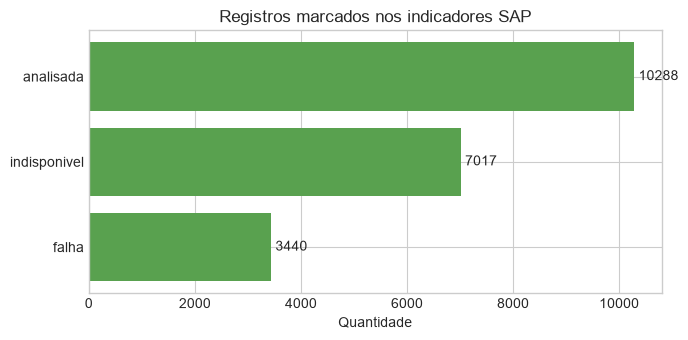

In [9]:
contagem_indicadores = df_limpo[[f"{c}_flag" for c in colunas_indicadoras]].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(contagem_indicadores.index.str.replace("_flag", ""), contagem_indicadores.values, color="#59A14F")
ax.set(title="Registros marcados nos indicadores SAP", xlabel="Quantidade", ylabel="")
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()

In [10]:
relacao_analise = pd.crosstab(
    df_limpo["analisada_flag"],
    df_limpo["data_analise"].isna(),
    rownames=["analisada_flag"],
    colnames=["data_analise_ausente"],
)

relacao_analise

data_analise_ausente,False,True
analisada_flag,,
False,33,326
True,4792,5496


A marca de análise e a data de análise não são equivalentes nesta extração. Por isso, ambas são preservadas sem imputação.

## 5. Duplicidades e qualidade dos identificadores

In [11]:
colunas_deduplicacao = [
    normalizar_coluna(coluna)
    for coluna in df.columns
    if normalizar_coluna(coluna) != "iqm"
]

ordens_repetidas = df_limpo.loc[
    df_limpo["ordem"].notna() & df_limpo["ordem"].duplicated(keep=False)
].copy()

comparacao = (
    ordens_repetidas.groupby("ordem")[
        [coluna for coluna in colunas_deduplicacao if coluna != "ordem"]
    ].nunique(dropna=False)
)
divergencias_por_ordem = comparacao.apply(
    lambda linha: linha[linha > 1].index.tolist(), axis=1
)
divergencias_por_ordem = divergencias_por_ordem[divergencias_por_ordem.str.len() > 0]

resumo_duplicidades = pd.Series({
    "linhas_em_ordens_repetidas": len(ordens_repetidas),
    "ordens_repetidas_distintas": ordens_repetidas["ordem"].nunique(),
    "ordens_repetidas_com_divergencia": len(divergencias_por_ordem),
    "ordens_ausentes": df_limpo["ordem"].isna().sum(),
    "duplicatas_exatas_excedentes": df_limpo.duplicated(
        subset=colunas_deduplicacao, keep="first"
    ).sum(),
})

resumo_duplicidades

linhas_em_ordens_repetidas          138
ordens_repetidas_distintas           67
ordens_repetidas_com_divergencia     66
ordens_ausentes                       2
duplicatas_exatas_excedentes          1
dtype: int64

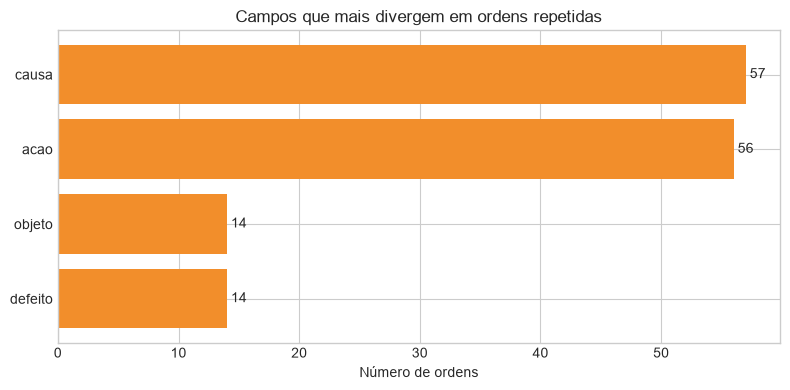

In [12]:
frequencia_divergencias = divergencias_por_ordem.explode().value_counts().head(10).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(frequencia_divergencias.index, frequencia_divergencias.values, color="#F28E2B")
ax.set(title="Campos que mais divergem em ordens repetidas", xlabel="Número de ordens", ylabel="")
ax.bar_label(ax.containers[0], padding=3)
plt.tight_layout()
plt.show()

In [13]:
duplicada_excedente = df_limpo.duplicated(
    subset=colunas_deduplicacao, keep="first"
)
duplicatas_removidas = int(duplicada_excedente.sum())

df_limpo = df_limpo.loc[~duplicada_excedente].copy().reset_index(drop=True)

print(f"Duplicatas exatas removidas: {duplicatas_removidas}")
print(f"Linhas após deduplicação: {len(df_limpo)}")

Duplicatas exatas removidas: 1
Linhas após deduplicação: 10646


Ordens repetidas com conteúdo divergente são mantidas. Somente duplicatas exatas são removidas.

## 6. Análise e tratamento de outliers de duração

A duração é calculada em horas. O percentil 99 é usado como regra estatística de corte definida para esta limpeza. Valores acima do limite são removidos da base final, mas preservados em uma tabela de auditoria.

In [14]:
df_limpo["duracao_avaria_horas"] = (
    df_limpo["fim_avaria_datetime"] - df_limpo["inicio_avaria_datetime"]
).dt.total_seconds().div(3600)

limite_99 = df_limpo["duracao_avaria_horas"].quantile(0.99)
limite_999 = df_limpo["duracao_avaria_horas"].quantile(0.999)

resumo_duracao = df_limpo["duracao_avaria_horas"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
)
print(f"Limite adotado (P99): {limite_99:.2f} horas")
resumo_duracao

Limite adotado (P99): 25.00 horas


count    10320.000000
mean         4.788219
std         94.819278
min          0.000000
50%          0.650000
90%          2.016667
95%          4.166667
99%         25.000000
99.9%      831.632015
max       7167.983333
Name: duracao_avaria_horas, dtype: float64

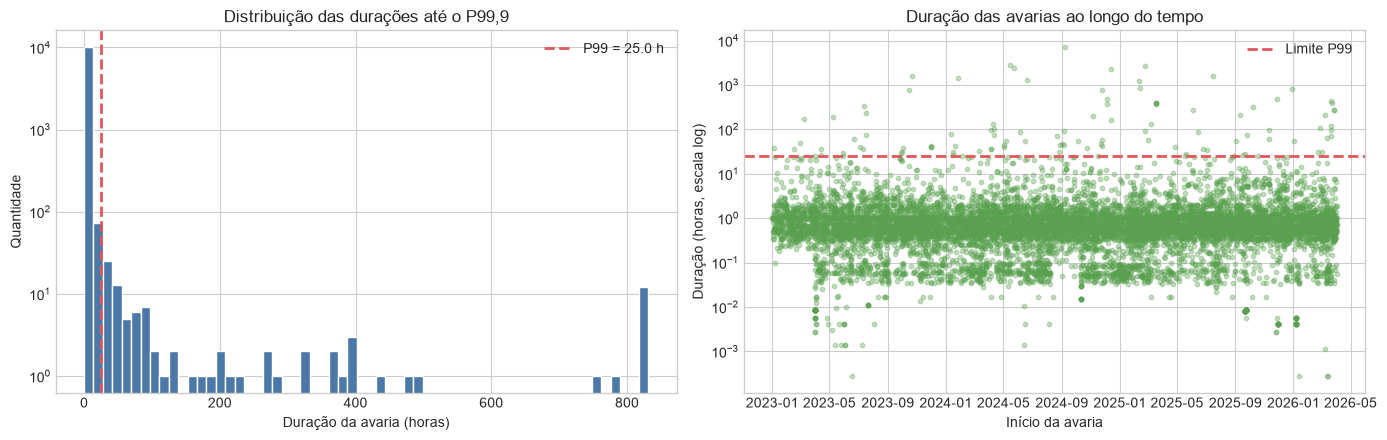

In [15]:
duracoes = df_limpo["duracao_avaria_horas"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(
    duracoes.clip(upper=limite_999),
    bins=60,
    color="#4C78A8",
    edgecolor="white",
)
axes[0].axvline(limite_99, color="#E15759", linestyle="--", linewidth=2, label=f"P99 = {limite_99:.1f} h")
axes[0].set(
    title="Distribuição das durações até o P99,9",
    xlabel="Duração da avaria (horas)",
    ylabel="Quantidade",
)
axes[0].set_yscale("log")
axes[0].legend()

duracoes_positivas = df_limpo.loc[df_limpo["duracao_avaria_horas"] > 0]
axes[1].scatter(
    duracoes_positivas["inicio_avaria_datetime"],
    duracoes_positivas["duracao_avaria_horas"],
    s=10,
    alpha=0.35,
    color="#59A14F",
)
axes[1].axhline(limite_99, color="#E15759", linestyle="--", linewidth=2, label="Limite P99")
axes[1].set_yscale("log")
axes[1].set(
    title="Duração das avarias ao longo do tempo",
    xlabel="Início da avaria",
    ylabel="Duração (horas, escala log)",
)
axes[1].legend()

plt.tight_layout()
plt.show()

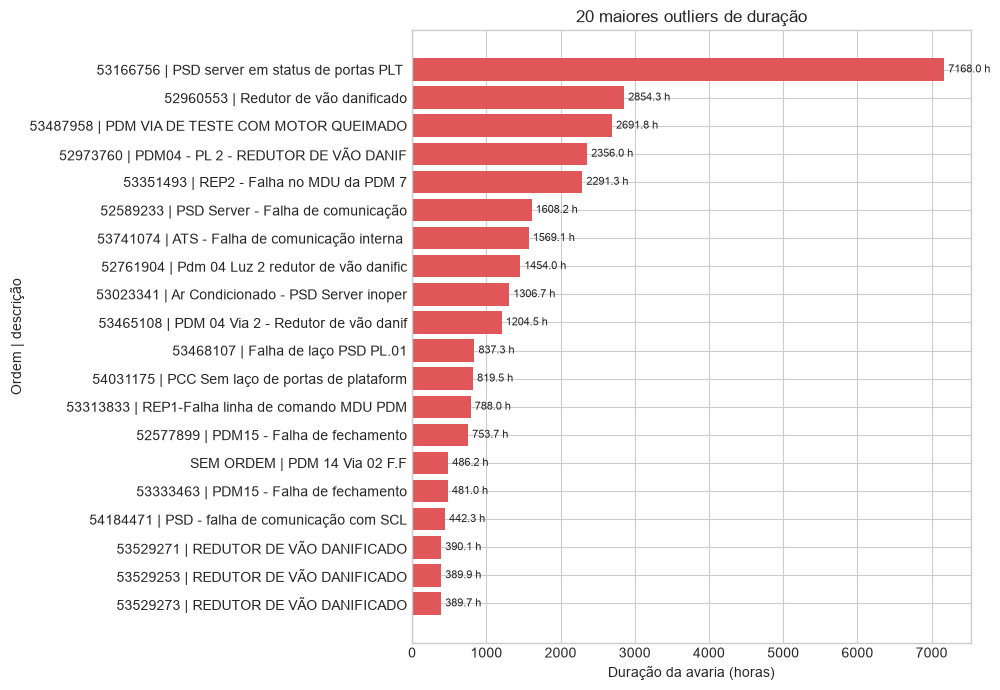

,linha_origem,nota,ordem,descricao,inicio_avaria_datetime,fim_avaria_datetime,duracao_avaria_horas
2713,2715,14153301,53166756,PSD server em status de portas PLT 1 e 2,2024-09-07 08:11:00,2025-07-03 00:10:00,7167.983333
4551,4553,13942455,52960553,Redutor de vão danificado,2024-05-15 06:00:00,2024-09-11 04:17:20,2854.288889
8586,8589,14474367,53487958,PDM VIA DE TESTE COM MOTOR QUEIMADO,2025-02-23 00:45:00,2025-06-15 04:30:00,2691.750000
6623,6626,13956048,52973760,PDM04 - PL 2 - REDUTOR DE VÃO DANIFICADO,2024-05-22 16:00:00,2024-08-28 20:00:00,2356.000000
9747,9750,14336758,53351493,REP2 - Falha no MDU da PDM 7,2024-12-14 07:13:11,2025-03-19 18:31:23,2291.303333
761,763,13560285,52589233,PSD Server - Falha de comunicação,2023-10-21 09:51:00,2023-12-27 10:00:00,1608.150000
15,17,14729737,53741074,ATS - Falha de comunicação interna PLT01,2025-07-16 18:54:00,2025-09-20 04:00:00,1569.100000
4984,4987,13738378,52761904,Pdm 04 Luz 2 redutor de vão danificado,2024-01-26 09:00:00,2024-03-26 23:00:00,1454.000000
7235,7238,14007763,53023341,Ar Condicionado - PSD Server inoperante,2024-06-20 03:49:00,2024-08-13 14:30:00,1306.683333
493,495,14452189,53465108,PDM 04 Via 2 - Redutor de vão danificado,2025-02-10 22:30:00,2025-04-02 03:00:00,1204.500000


In [16]:
outliers_duracao = df_limpo.loc[
    df_limpo["duracao_avaria_horas"] > limite_99
].copy()

maiores_outliers = outliers_duracao.nlargest(20, "duracao_avaria_horas").sort_values("duracao_avaria_horas")
rotulos = maiores_outliers["ordem"].fillna("SEM ORDEM") + " | " + maiores_outliers["descricao"].str.slice(0, 35)

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(rotulos, maiores_outliers["duracao_avaria_horas"], color="#E15759")
ax.set(title="20 maiores outliers de duração", xlabel="Duração da avaria (horas)", ylabel="Ordem | descrição")
ax.bar_label(ax.containers[0], fmt="%.1f h", padding=3, fontsize=8)
plt.tight_layout()
plt.show()

outliers_duracao[[
    "linha_origem", "nota", "ordem", "descricao",
    "inicio_avaria_datetime", "fim_avaria_datetime", "duracao_avaria_horas"
]].nlargest(20, "duracao_avaria_horas")

In [17]:
df_limpo = df_limpo.loc[
    df_limpo["duracao_avaria_horas"].isna()
    | df_limpo["duracao_avaria_horas"].le(limite_99)
].copy().reset_index(drop=True)

print(f"Outliers preservados para auditoria: {len(outliers_duracao)}")
print(f"Maior duração restante: {df_limpo['duracao_avaria_horas'].max():.2f} horas")
print(f"Linhas após a remoção dos outliers: {len(df_limpo)}")

Outliers preservados para auditoria: 103
Maior duração restante: 25.00 horas
Linhas após a remoção dos outliers: 10543


## 7. Preparação da base final

In [18]:
df_final = df_limpo.copy()

df_final["ordem_ausente_flag"] = df_final["ordem"].isna()
df_final["ordem_repetida_flag"] = (
    df_final["ordem"].notna() & df_final["ordem"].duplicated(keep=False)
)

colunas_temporarias = [
    "inicio_avaria", "hora_inicio_avaria", "hora_inicio_avaria_convertida",
    "fim_da_avaria", "hora_do_fim_da_avaria", "hora_do_fim_da_avaria_convertida",
    "data_analise", "hora_analise", "hora_analise_convertida",
    "encerram_por_data", "hora_de_encerramento", "hora_de_encerramento_convertida",
    "indisponivel", "falha", "analisada",
]
df_final.drop(columns=colunas_temporarias, inplace=True, errors="ignore")

colunas_inicio = [
    "linha_origem", "tipo_de_nota", "nota", "ordem", "perfil_do_catalogo",
    "descricao", "local_de_instalacao", "centro_de_trabalho_responsavel",
    "inicio_avaria_datetime", "fim_avaria_datetime", "duracao_avaria_horas",
    "analise_datetime", "encerramento_datetime", "indisponivel_flag",
    "falha_flag", "analisada_flag", "ordem_ausente_flag", "ordem_repetida_flag",
]
df_final = df_final[colunas_inicio + [c for c in df_final.columns if c not in colunas_inicio]]

df_final.info()

<class 'pandas.DataFrame'>
RangeIndex: 10543 entries, 0 to 10542
Data columns (total 27 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   linha_origem                          10543 non-null  int64         
 1   tipo_de_nota                          10543 non-null  string        
 2   nota                                  10543 non-null  string        
 3   ordem                                 10542 non-null  string        
 4   perfil_do_catalogo                    10543 non-null  string        
 5   descricao                             10543 non-null  string        
 6   local_de_instalacao                   10543 non-null  string        
 7   centro_de_trabalho_responsavel        10543 non-null  string        
 8   inicio_avaria_datetime                10543 non-null  datetime64[us]
 9   fim_avaria_datetime                   10217 non-null  datetime64[us]
 10  duracao_a

In [19]:
outliers_final = outliers_duracao.copy()
outliers_final["ordem_ausente_flag"] = outliers_final["ordem"].isna()
outliers_final["ordem_repetida_flag"] = (
    outliers_final["ordem"].notna() & outliers_final["ordem"].duplicated(keep=False)
)
outliers_final.drop(columns=colunas_temporarias, inplace=True, errors="ignore")
outliers_final = outliers_final[df_final.columns]

relatorio_ausentes_final = pd.DataFrame({
    "coluna": df_final.columns,
    "quantidade_ausente": [df_final[c].isna().sum() for c in df_final.columns],
    "percentual_ausente": [round(df_final[c].isna().mean() * 100, 2) for c in df_final.columns],
}).sort_values("percentual_ausente", ascending=False)

relatorio_ausentes_final.head(12)

,coluna,quantidade_ausente,percentual_ausente
11,analise_datetime,5756,54.60
18,comentarios_classificacao_engenharia,2806,26.61
25,causa,1036,9.83
26,acao,982,9.31
24,defeito,977,9.27
23,objeto,973,9.23
9,fim_avaria_datetime,326,3.09
10,duracao_avaria_horas,326,3.09
20,texto_longo_da_ordem,61,0.58
12,encerramento_datetime,1,0.01


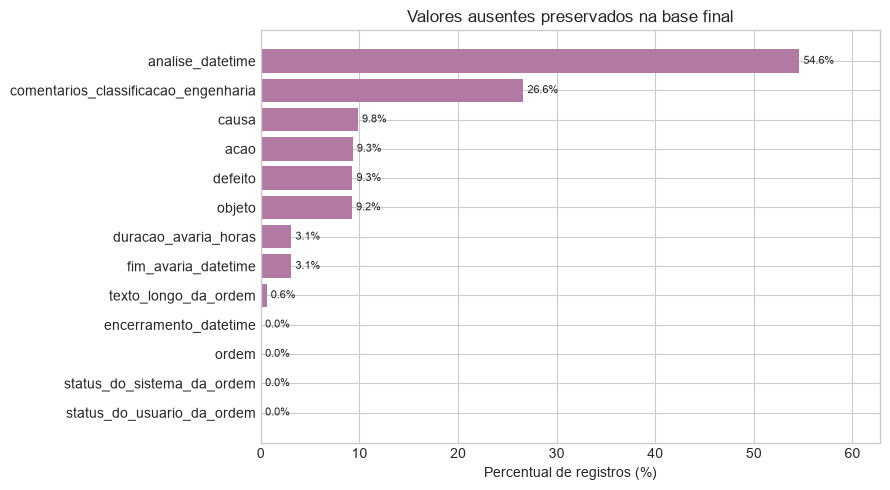

In [20]:
ausentes_finais = relatorio_ausentes_final.query("percentual_ausente > 0").sort_values("percentual_ausente")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ausentes_finais["coluna"], ausentes_finais["percentual_ausente"], color="#B279A2")
ax.set(title="Valores ausentes preservados na base final", xlabel="Percentual de registros (%)", ylabel="")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
ax.set_xlim(0, max(ausentes_finais["percentual_ausente"].max() * 1.15, 1))
plt.tight_layout()
plt.show()

## 8. Validação final e documentação

In [21]:
decisoes_limpeza = {
    "iqm": "Coluna removida por conter 100% de valores ausentes.",
    "duplicatas": f"Removidas {duplicatas_removidas} linha(s) exatamente duplicada(s).",
    "duracao_avaria_horas": (
        f"Removidos {len(outliers_duracao)} registros acima do percentil 99 "
        f"({limite_99:.2f} horas), preservados separadamente para auditoria."
    ),
    "fim_da_avaria": "Ausências preservadas; não foi realizada imputação.",
    "data_analise": "Ausências preservadas; marca e data de análise não são equivalentes.",
    "campos_catalogo": "Ausências de objeto, defeito, causa e ação foram preservadas.",
    "ordens_ausentes": "Registros sem ordem foram mantidos quando possuíam nota e dados úteis.",
}

relatorio_decisoes = pd.DataFrame(
    decisoes_limpeza.items(), columns=["campo_ou_regra", "decisao"]
)
relatorio_decisoes

,campo_ou_regra,decisao
0,iqm,Coluna removida por conter 100% de valores aus...
1,duplicatas,Removidas 1 linha(s) exatamente duplicada(s).
2,duracao_avaria_horas,Removidos 103 registros acima do percentil 99 ...
3,fim_da_avaria,Ausências preservadas; não foi realizada imput...
4,data_analise,Ausências preservadas; marca e data de análise...
5,campos_catalogo,"Ausências de objeto, defeito, causa e ação for..."
6,ordens_ausentes,Registros sem ordem foram mantidos quando poss...


In [22]:
validacao_final = pd.Series({
    "linhas_originais": len(df),
    "duplicatas_removidas": duplicatas_removidas,
    "outliers_removidos": len(outliers_final),
    "linhas_finais": len(df_final),
    "colunas_finais": df_final.shape[1],
    "duplicatas_exatas_restantes": df_final.duplicated().sum(),
    "ordens_ausentes": df_final["ordem"].isna().sum(),
    "notas_ausentes": df_final["nota"].isna().sum(),
    "duracoes_negativas": df_final["duracao_avaria_horas"].lt(0).sum(),
    "duracoes_acima_limite": df_final["duracao_avaria_horas"].gt(limite_99).sum(),
    "colunas_duplicadas": df_final.columns.duplicated().sum(),
})

assert len(df) == len(df_final) + len(outliers_final) + duplicatas_removidas
assert df_final["nota"].dtype.name == "string"
assert df_final["ordem"].dtype.name == "string"
assert df_final["inicio_avaria_datetime"].notna().all()
assert not df_final["duracao_avaria_horas"].lt(0).any()
assert not df_final["duracao_avaria_horas"].gt(limite_99).any()
assert not df_final.columns.duplicated().any()

validacao_final

linhas_originais               10647
duplicatas_removidas               1
outliers_removidos               103
linhas_finais                  10543
colunas_finais                    27
duplicatas_exatas_restantes        0
ordens_ausentes                    1
notas_ausentes                     0
duracoes_negativas                 0
duracoes_acima_limite              0
colunas_duplicadas                 0
dtype: int64

## 9. Exportação

O arquivo original não é sobrescrito. A saída contém a base limpa, os outliers removidos e os relatórios de ausências e decisões.

In [23]:
pasta_saida = Path(caminho).parent / "processados"
pasta_saida.mkdir(parents=True, exist_ok=True)
arquivo_saida = pasta_saida / "ZM01_limpa.xlsx"

with pd.ExcelWriter(arquivo_saida, engine="openpyxl") as writer:
    df_final.to_excel(writer, sheet_name="ZM01_limpa", index=False)
    outliers_final.to_excel(writer, sheet_name="Outliers_removidos", index=False)
    relatorio_ausentes_final.to_excel(writer, sheet_name="Qualidade_ausencias", index=False)
    relatorio_decisoes.to_excel(writer, sheet_name="Decisoes_limpeza", index=False)

print("Arquivo exportado para:", arquivo_saida.resolve())

Arquivo exportado para: C:\Users\joaop\Documents\Projetos Inteli\Modulo 7\g04\data\Corretiva Emergencial\processados\ZM01_limpa.xlsx
